In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import euclidean, cityblock, minkowski, mahalanobis
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import re
import warnings

warnings.filterwarnings('ignore')

# Visual Styling & Plot Customization Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 110

# Ingest Washington State EV Dataset
DATASET_PATH = 'C:/VS/DS_LabCA/Data_set_for_labCA.csv'
df = pd.read_csv(DATASET_PATH)

print("=" * 80)
print("     WASHINGTON STATE ELECTRIC VEHICLE FLEET: INGESTION SUMMARY")
print("=" * 80)
print(f"Total Fleet Records (n)         : {df.shape[0]:,}")
print(f"Total Recorded Attributes (p)   : {df.shape[1]}")
print(f"Memory Footprint in RAM         : {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print("=" * 80)

# Display First 5 Representative Records
df.head(5)

     WASHINGTON STATE ELECTRIC VEHICLE FLEET: INGESTION SUMMARY
Total Fleet Records (n)         : 299,705
Total Recorded Attributes (p)   : 16
Memory Footprint in RAM         : 209.05 MB


,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,1N4AZ1CP3K,King,Shoreline,WA,98155.0,2019,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,150.0,32.0,168526641,POINT (-122.30304 47.75494),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,WBY8P4C51K,King,Kirkland,WA,98033.0,2019,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,126.0,48.0,9418181,POINT (-122.2066 47.67887),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303302e+10
2,3FA6P0SU8G,Snohomish,Lynnwood,WA,98036.0,2016,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,1.0,172853495,POINT (-122.29245 47.82557),PUGET SOUND ENERGY INC,5.306105e+10
3,5YJ3E1EB3N,Yakima,Wapato,WA,98951.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,15.0,204768175,POINT (-120.42083 46.44779),PACIFICORP,5.307794e+10
4,WBY1Z2C53F,King,Renton,WA,98055.0,2015,BMW,I3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,81.0,11.0,269262920,POINT (-122.19488 47.44034),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),5.303303e+10


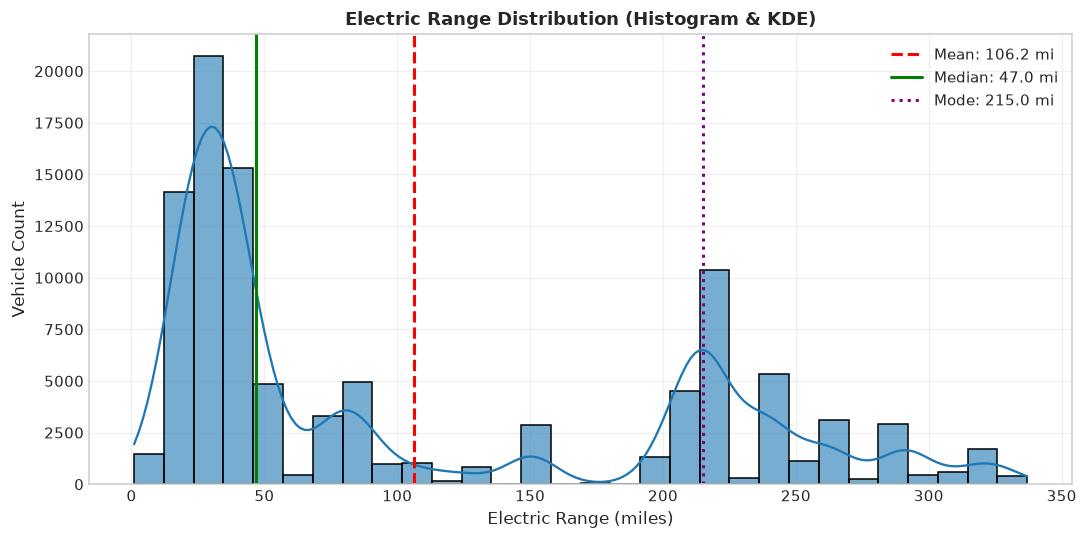

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 5))
s_hist = df[df['Electric_Range_Raw'] > 0]['Electric_Range_Raw']

# Histogram with KDE Overlay
sns.histplot(
    s_hist, 
    bins=30, 
    kde=True, 
    color='#1f77b4', 
    edgecolor='black', 
    alpha=0.6, 
    ax=ax
)

# Reference Lines (Mean, Median, Mode)
ax.axvline(raw_mean, color='red', linestyle='--', linewidth=2, label=f"Mean: {raw_mean:.1f} mi")
ax.axvline(raw_median, color='green', linestyle='-', linewidth=2, label=f"Median: {raw_median:.1f} mi")
ax.axvline(raw_mode, color='purple', linestyle=':', linewidth=2, label=f"Mode: {raw_mode:.1f} mi")

# Formatting
ax.set_title("Electric Range Distribution (Histogram & KDE)", fontweight='bold')
ax.set_xlabel("Electric Range (miles)")
ax.set_ylabel("Vehicle Count")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.2 Distribution Spread, Outliers & Normality Diagnostics (Boxplots & Q-Q Plots)

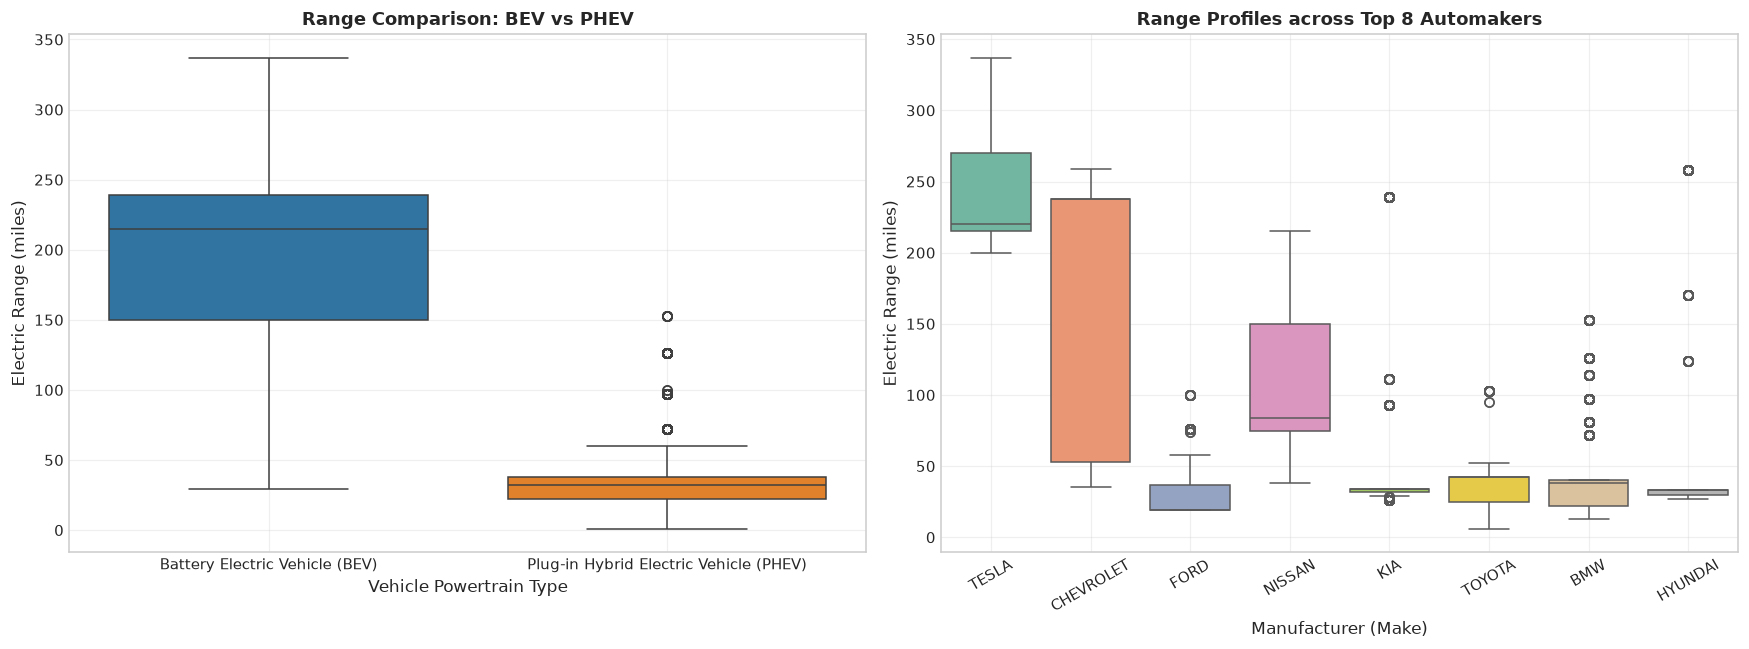

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Spread & Comparative Diagnostics (BEV vs PHEV & Top 8 Automakers)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Comparative Boxplot by Powertrain Architecture (BEV vs PHEV)
sub_sample = df[df["Electric_Range_Raw"] > 0]
sns.boxplot(
    data=sub_sample,
    x="Electric Vehicle Type",
    y="Electric_Range_Raw",
    palette=["#1f77b4", "#ff7f0e"],
    ax=axes[0],
)
axes[0].set_title("Range Comparison: BEV vs PHEV", fontweight="bold")
axes[0].set_xlabel("Vehicle Powertrain Type")
axes[0].set_ylabel("Electric Range (miles)")
axes[0].grid(True, alpha=0.3)

# Subplot 2: Comparative Boxplot across Top 8 Automakers
top_8_makes = df["Make"].value_counts().head(8).index
sub_top8 = df[(df["Make"].isin(top_8_makes)) & (df["Electric_Range_Raw"] > 0)]
sns.boxplot(
    data=sub_top8,
    x="Make",
    y="Electric_Range_Raw",
    order=top_8_makes,
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title(
    "Range Profiles across Top 8 Automakers", fontweight="bold"
)
axes[1].set_xlabel("Man ufacturer (Make)")
axes[1].set_ylabel("Electric Range (miles)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

               SCOREBOARD: WASHINGTON STATE EV FLEET
|  TOTAL FLEET SIZE  |  BEV MARKET SHARE  |  MEAN FLEET RANGE  |  MEDIAN MODEL YR  |
|    299,705      |      80.7%        |     180.8 mi      |       2023        |
--------------------------------------------------------------------------------
|  CAFV ELIGIBILITY  |  KING CO. DENSITY  |  TOP MAKE (TESLA)  |  RESEARCHED SHARE |
|      26.5%        |      48.1%        |     41.0%        |       34.5%        |


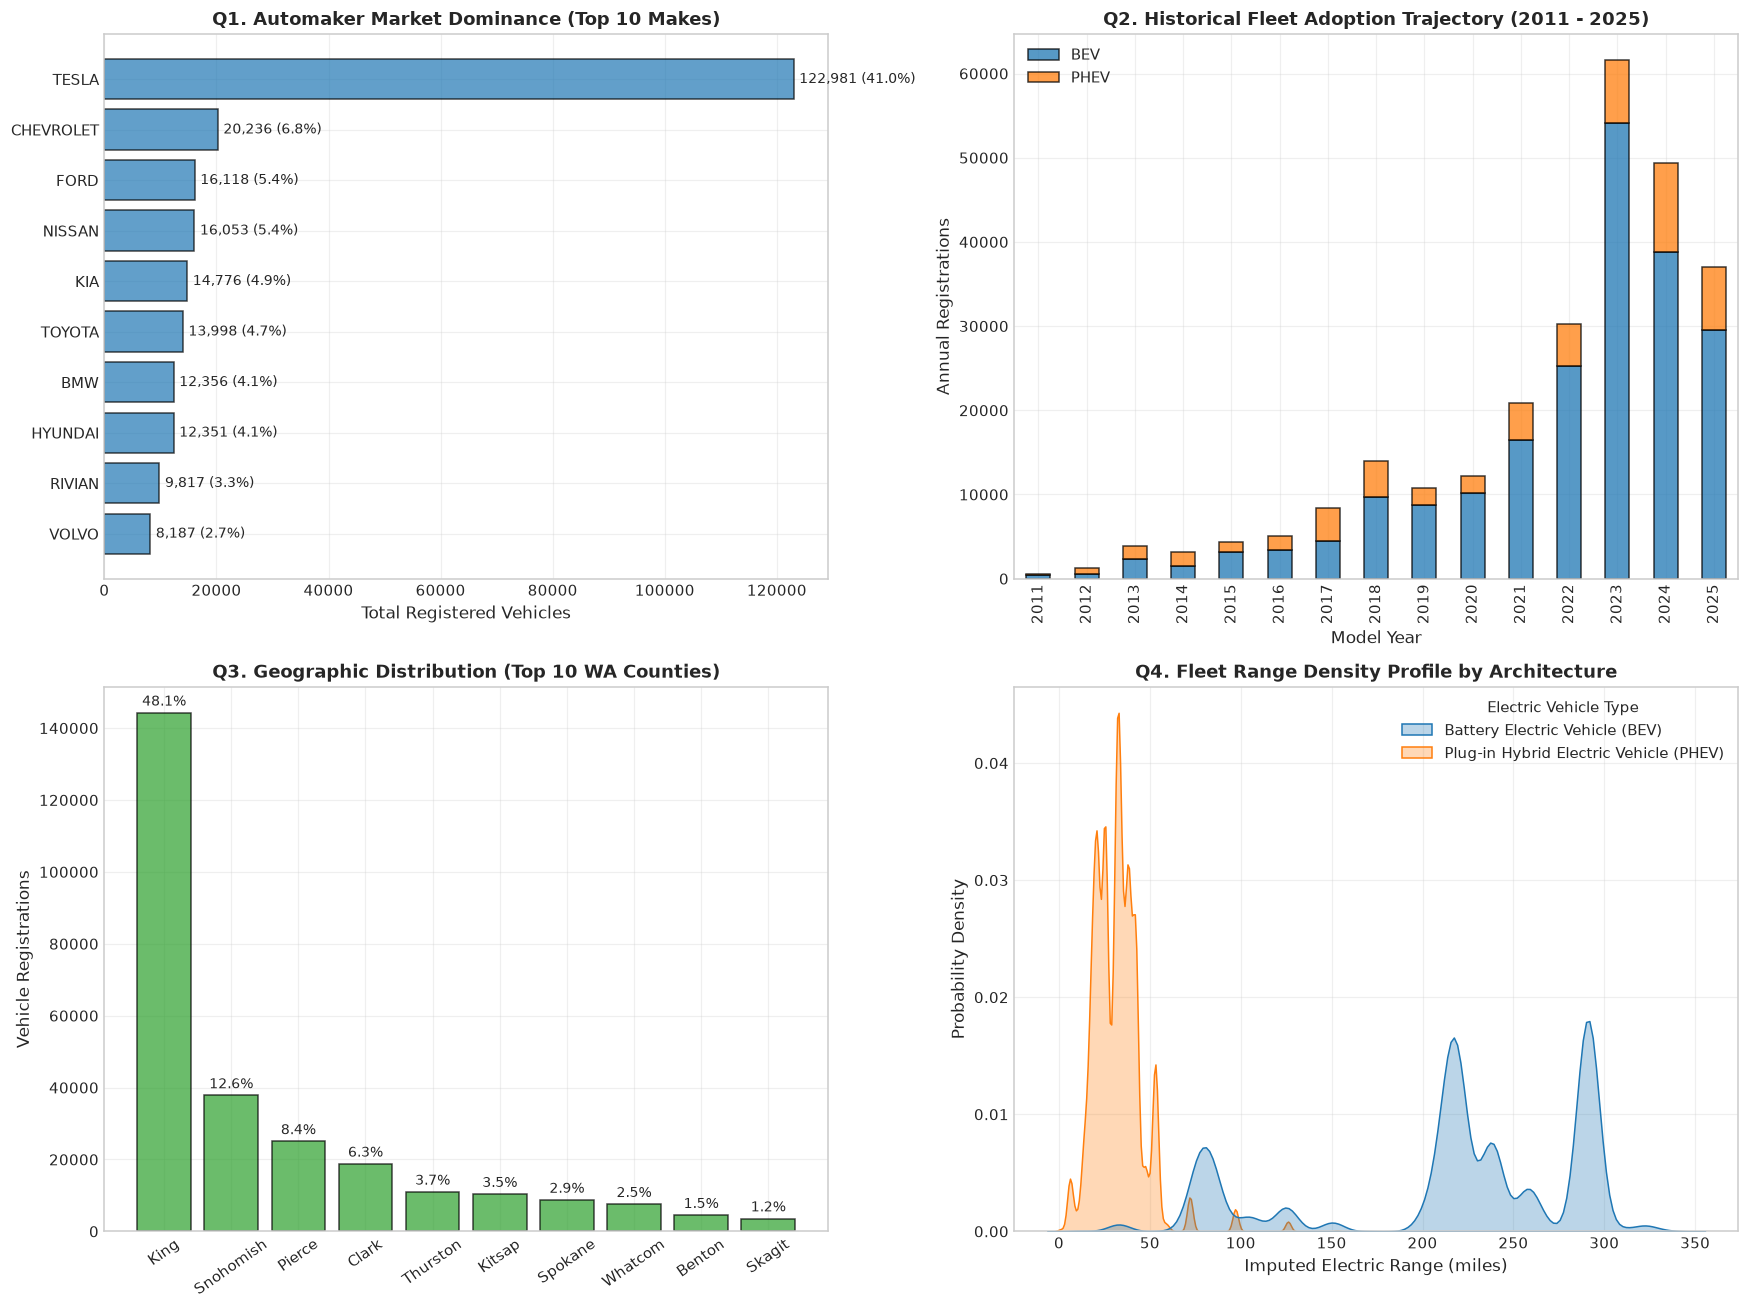

In [27]:
# 5. Executive Dashboard & High-Level KPI Scoreboard
# Part 1: High-Level KPI Metrics Calculation
total_fleet = len(df)
bev_count = (df['Electric Vehicle Type'] == 'Battery Electric Vehicle (BEV)').sum()
bev_share = (bev_count / total_fleet) * 100.0
mean_fleet_range = df['Electric_Range_Imputed'].mean()
median_model_year = int(df['Model Year'].median())
cafv_eligible_count = (df['Clean Alternative Fuel Vehicle (CAFV) Eligibility'] == 'Clean Alternative Fuel Vehicle Eligible').sum()
cafv_eligible_pct = (cafv_eligible_count / total_fleet) * 100.0
king_county_pct = ((df['County'] == 'King').sum() / total_fleet) * 100.0

# Print KPI Scoreboard Cards in Console
print("=" * 80)
print("               SCOREBOARD: WASHINGTON STATE EV FLEET")
print("=" * 80)
print(f"|  TOTAL FLEET SIZE  |  BEV MARKET SHARE  |  MEAN FLEET RANGE  |  MEDIAN MODEL YR  |")
print(f"|    {total_fleet:,}      |      {bev_share:.1f}%        |     {mean_fleet_range:.1f} mi      |       {median_model_year}        |")
print("-" * 80)
print(f"|  CAFV ELIGIBILITY  |  KING CO. DENSITY  |  TOP MAKE (TESLA)  |  RESEARCHED SHARE |")
print(f"|      {cafv_eligible_pct:.1f}%        |      {king_county_pct:.1f}%        |     {(df['Make']=='TESLA').mean()*100:.1f}%        |       {pos_range/total_fleet*100:.1f}%        |")
print("=" * 80)

# Part 2: Integrated 4-Quadrant Operational Analytics Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Quadrant 1: Top 10 EV Automakers Fleet Volume
top_makes = df['Make'].value_counts().head(10)
axes[0, 0].barh(top_makes.index[::-1], top_makes.values[::-1], color='#1f77b4', edgecolor='black', alpha=0.7)
for i, v in enumerate(top_makes.values[::-1]):
    axes[0, 0].text(v + 1000, i, f"{v:,} ({v/total_fleet*100:.1f}%)", va='center', fontsize=9)
axes[0, 0].set_title("Q1. Automaker Market Dominance (Top 10 Makes)", fontweight='bold')
axes[0, 0].set_xlabel("Total Registered Vehicles")
axes[0, 0].grid(True, alpha=0.3)

# Quadrant 2: Historical Adoption Trajectory by Powertrain (2011 - 2025)
history_df = df[(df['Model Year'] >= 2011) & (df['Model Year'] <= 2025)].groupby(['Model Year', 'Electric Vehicle Type']).size().unstack(fill_value=0)
history_df.plot(kind='bar', stacked=True, color=['#1f77b4', '#ff7f0e'], ax=axes[0, 1], edgecolor='black', alpha=0.75)
axes[0, 1].set_title("Q2. Historical Fleet Adoption Trajectory (2011 - 2025)", fontweight='bold')
axes[0, 1].set_xlabel("Model Year")
axes[0, 1].set_ylabel("Annual Registrations")
axes[0, 1].legend(['BEV', 'PHEV'], loc='upper left')
axes[0, 1].grid(True, alpha=0.3)

# Quadrant 3: Geographic Distribution — Top 10 Washington Counties
top_counties = df[df['State'] == 'WA']['County'].value_counts().head(10)
axes[1, 0].bar(top_counties.index, top_counties.values, color='#2ca02c', edgecolor='black', alpha=0.7)
for i, v in enumerate(top_counties.values):
    axes[1, 0].text(i, v + 2000, f"{v/total_fleet*100:.1f}%", ha='center', fontsize=9)
axes[1, 0].set_title("Q3. Geographic Distribution (Top 10 WA Counties)", fontweight='bold')
axes[1, 0].set_ylabel("Vehicle Registrations")
axes[1, 0].tick_params(axis='x', rotation=35)
axes[1, 0].grid(True, alpha=0.3)

# Quadrant 4: Battery Architecture Range Density Comparison
sns.kdeplot(data=df[df['Electric_Range_Imputed'] > 0], x='Electric_Range_Imputed', hue='Electric Vehicle Type',
            palette=['#1f77b4', '#ff7f0e'], common_norm=False, fill=True, alpha=0.3, ax=axes[1, 1])
axes[1, 1].set_title("Q4. Fleet Range Density Profile by Architecture", fontweight='bold')
axes[1, 1].set_xlabel("Imputed Electric Range (miles)")
axes[1, 1].set_ylabel("Probability Density")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()